## Test training (CHEAT)


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00262ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d]'
00: ===========================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin_cheat 94cb65af/.
00: Launching 'AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 128 for valuation.
01:   This model has 47729 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_attin_cheat' epoch 1/1000 error avg trn 261.9; val 50.69/71.42 [37s 0.67s 0.17s]. LR: 1.00e-03, GN 14.84, excess_weighted: 0.003622/0.003471, excess_weighted_avg: 0.003699/0.003581, excess_spread: 56.32/71.95, exc

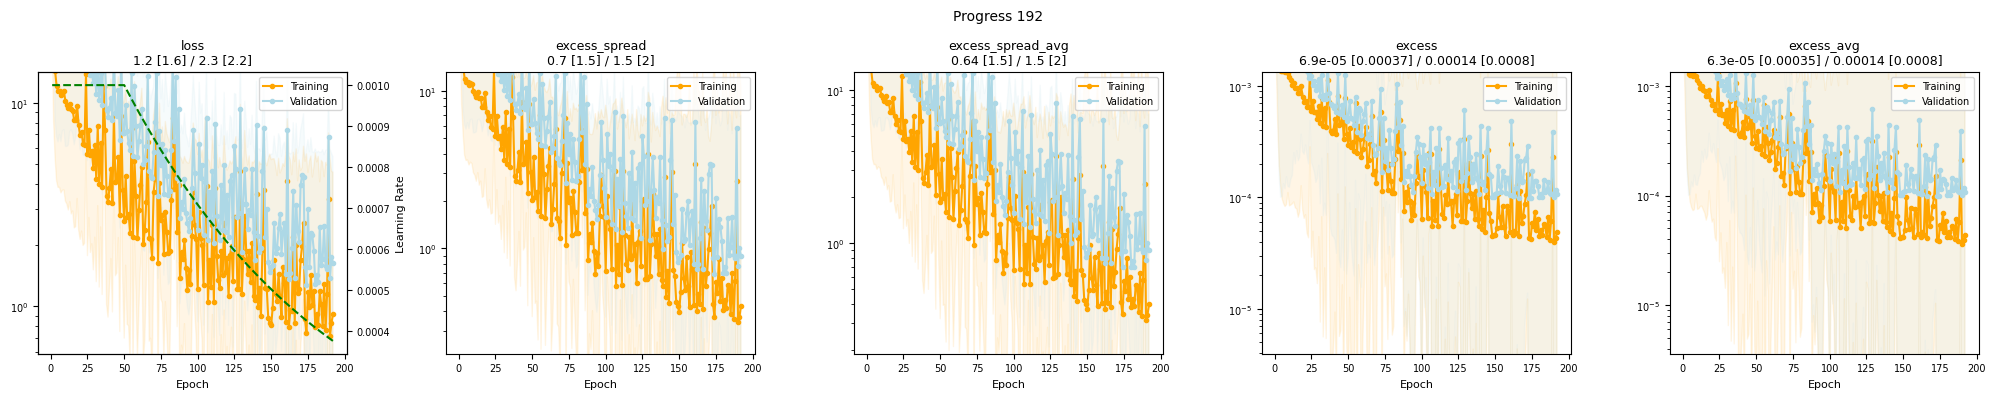

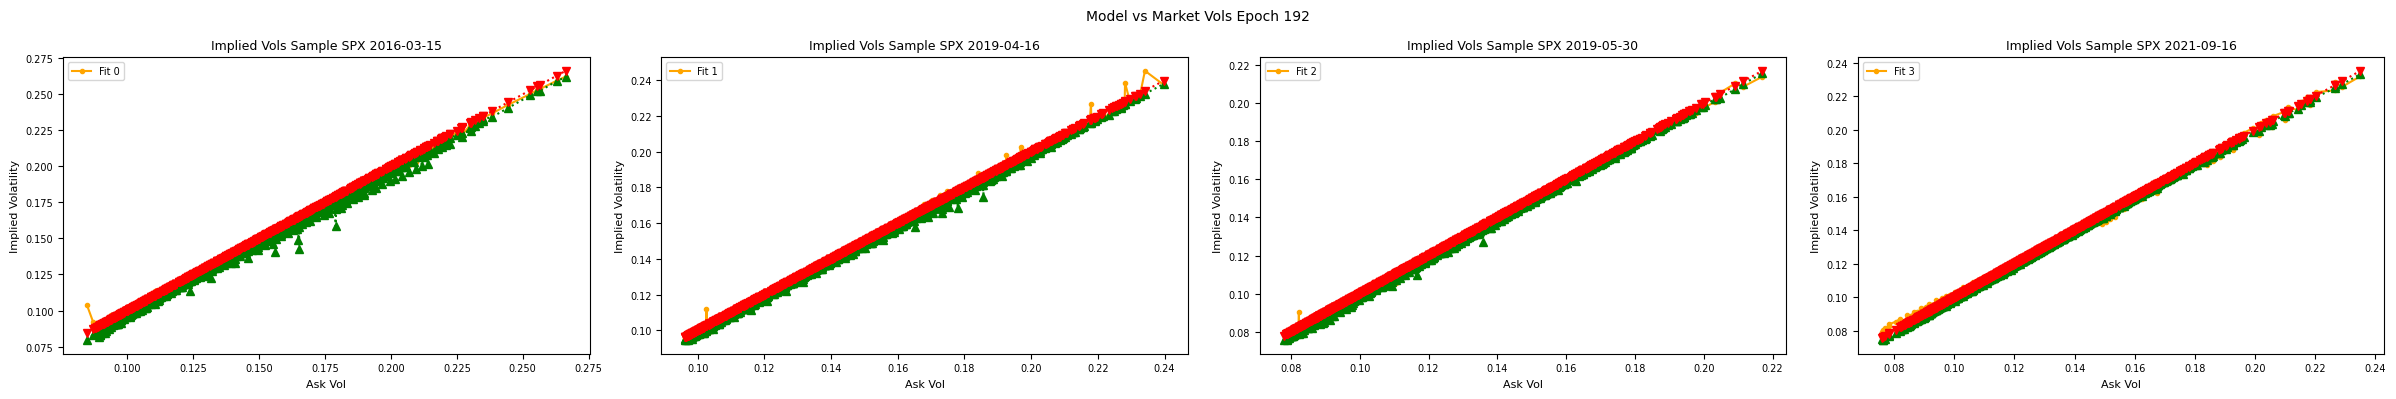

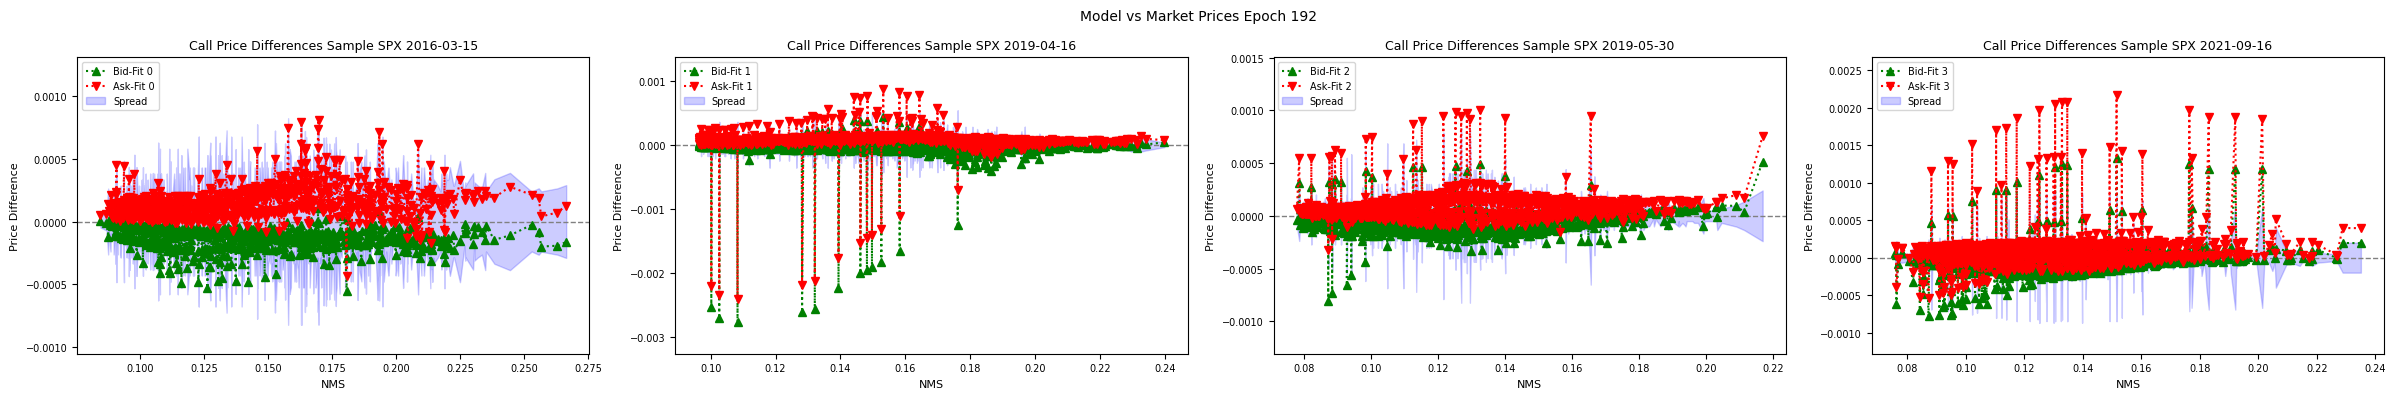

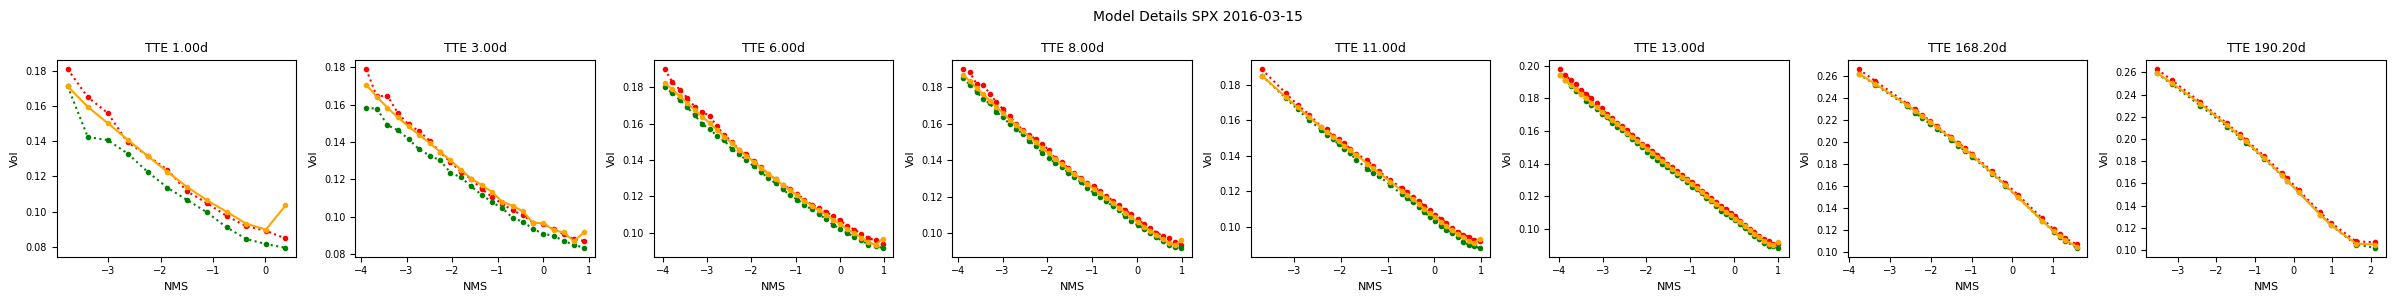

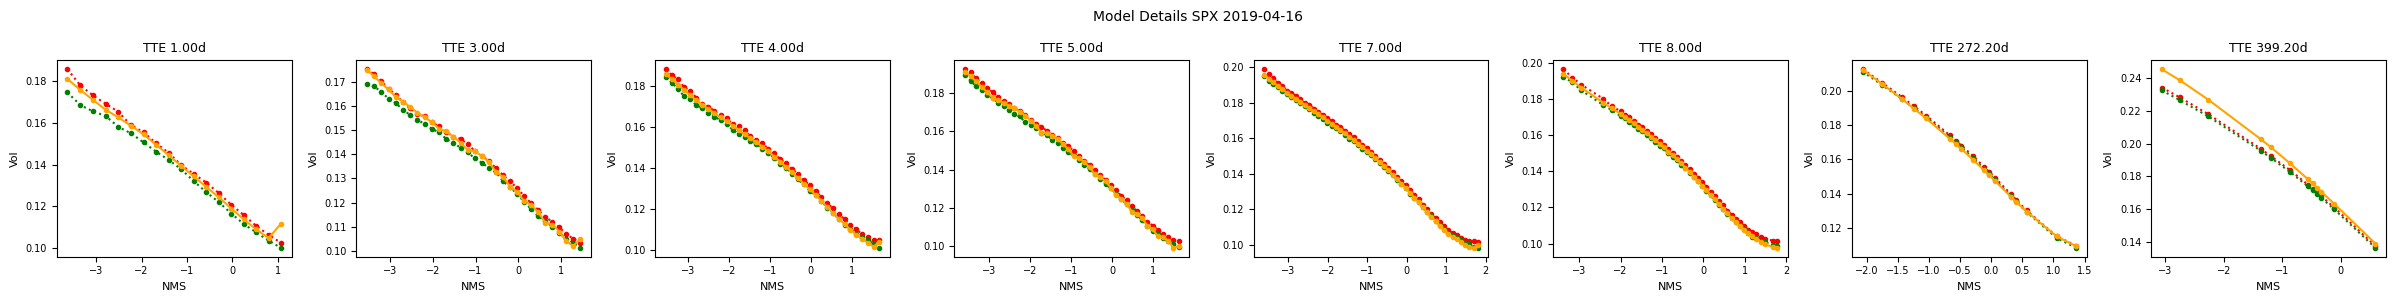

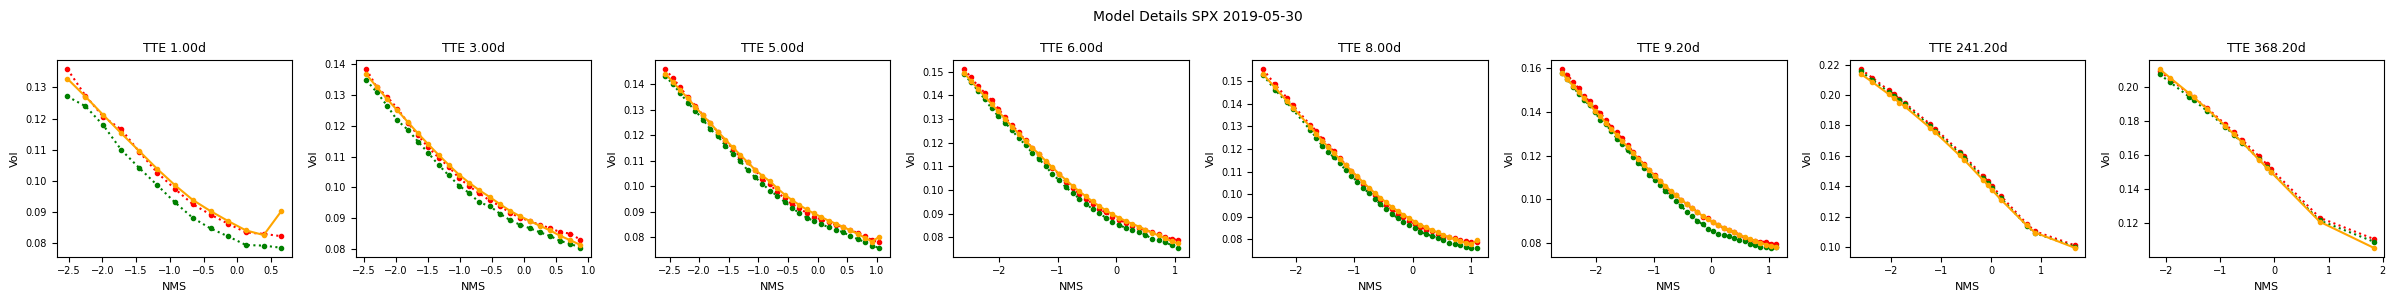

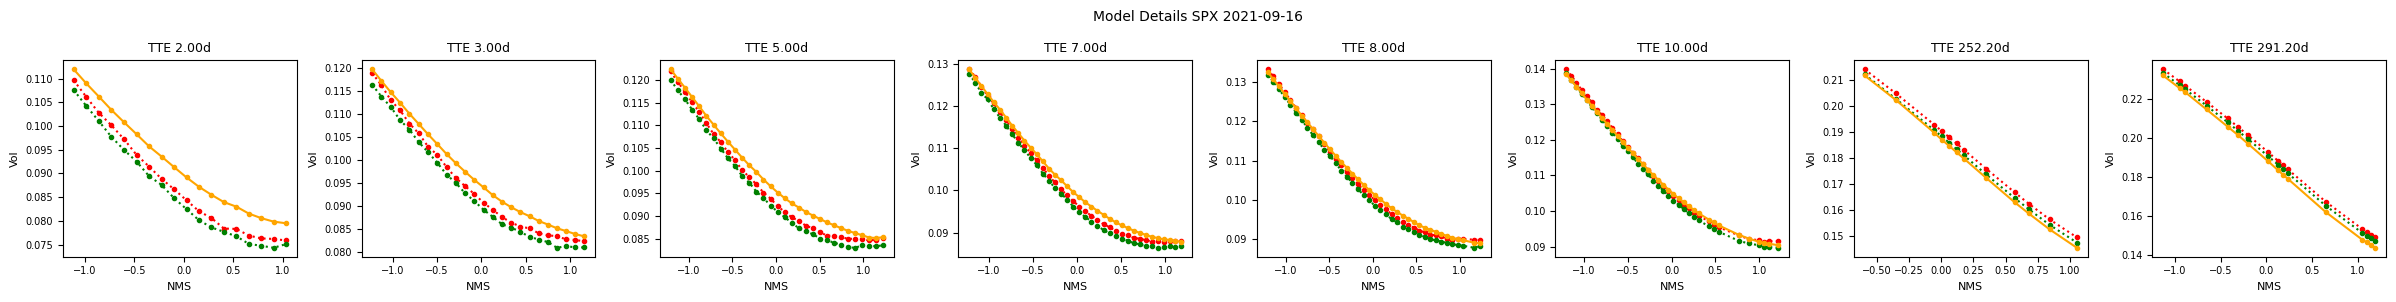

00: Training 'train_vol_vol_attin_cheat' epoch 2/1000 error avg trn 51.91; val 21.11/48.69 [1:14 0.67s 0.17s]. LR: 1.00e-03, GN 40.45, excess_weighted: 0.001419/0.002338, excess_weighted_avg: 0.001471/0.002355, excess_spread: 22.07/48.45, excess_spread_avg: 20.58/48.45, excess: 0.002077/0.002826, excess_avg: 0.002033/0.002826. ETA: 21:54:24.
00: Training 'train_vol_vol_attin_cheat' epoch 3/1000 error avg trn 22.1; val 14.32/20.84 [1:52 0.67s 0.17s]. LR: 1.00e-03, GN 172.7, excess_weighted: 0.0009496/0.0009654, excess_weighted_avg: 0.0009714/0.001113, excess_spread: 14.77/20.01, excess_spread_avg: 13.78/20.01, excess: 0.001506/0.001573, excess_avg: 0.001418/0.001573. ETA: 32:59:11.
01:   Epoch 3: Saving new best validation loss 20.84 vs. 71.42 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin_cheat 94cb65af/best.pt'... done; this took 0.017s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3c

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,
    cheat = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )


In [ ]:
sampler.data